# HW2 Part 1: Cleaning and validating `ohlc_hw`

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

db_path = Path('data/data.db')
if not db_path.is_file():
    raise FileNotFoundError(f'Copy the bCourses data.db to {db_path.resolve()}')

PRICE_COLS = ['open', 'high', 'low', 'close']
KEY = ['ticker', 'ts']
conn = sqlite3.connect(db_path)

## 1.1 Load and inspect the data

In [2]:
raw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)
raw_row_count = len(raw)
raw.info()
display(raw.describe())
display(raw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


,open,high,low,close,adj_close,volume
count,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
std,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08
min,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09


,ts,open,high,low,close,adj_close,volume,ticker
0,1975-04-14,5.4300,5.4800,5.3600,5.4400,1.640000,446392,CAT
1,1978-04-05,4.8400,4.8900,4.8100,4.8800,0.656990,355200,CVX
2,2018-05-25,124.5400,124.7600,121.2200,122.1900,92.220000,8936649,CVX
3,1995-12-07,9.9700,9.9700,9.8300,9.9400,5.880000,3954150,HD
4,1981-07-23,0.1038,0.1038,0.1038,0.1038,0.080013,34451232,AAPL


In [3]:
raw_dates = pd.to_datetime(raw['ts'])
print('Date range:', raw_dates.min().date(), 'to', raw_dates.max().date())
print('Distinct raw ticker labels:', raw['ticker'].nunique())
print('Examples:', raw['ticker'].unique()[:3].tolist())

Date range: 1962-01-02 to 2024-12-06
Distinct raw ticker labels: 150
Examples: ['CAT', 'CVX', 'HD']


### Normalizing ticker labels (before any grouping)

In [4]:
def normalize_tickers(frame):
    """Remove HTML tags and whitespace from tickers and upper-case them; keep the original label in ticker_raw."""
    out = frame.copy()
    out['ticker_raw'] = out['ticker']
    out['ticker'] = (out['ticker']
                     .str.replace(r'<[^>]+>', '', regex=True)
                     .str.strip()
                     .str.upper())
    return out

normalized = normalize_tickers(raw)
ticker_audit = normalized.groupby(['ticker', 'ticker_raw']).size().rename('rows').reset_index()
display(ticker_audit.head(5))
print(f"{raw['ticker'].nunique()} raw labels -> {normalized['ticker'].nunique()} tickers")
print('Tickers:', sorted(normalized['ticker'].unique()))
assert ticker_audit.groupby('ticker')['ticker_raw'].nunique().eq(5).all()

,ticker,ticker_raw,rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AA...",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: b...",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: b...",264
4,AAPL,AAPL,10747


150 raw labels -> 30 tickers
Tickers: ['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


### Exact duplicates vs. conflicting keys

In [5]:
def split_duplicates(frame):
    """Drop exact duplicate rows, then separate rows whose (ticker, ts) key still repeats (conflicts)."""
    deduped = frame.drop_duplicates()
    conflicting = deduped.duplicated(KEY, keep=False)
    return deduped.loc[~conflicting].copy(), deduped.loc[conflicting].copy()

records = normalized.drop(columns='ticker_raw')
unique_rows, conflicts = split_duplicates(records)
exact_duplicates_removed = len(records) - len(unique_rows) - len(conflicts)
print('Rows in ohlc_hw:           ', len(records))
print('Exact duplicates removed:  ', exact_duplicates_removed)
print('Conflicting (ticker, ts):  ', len(conflicts))
print('Unique rows remaining:     ', len(unique_rows))

data = unique_rows.copy()
data['ts'] = pd.to_datetime(data['ts'])
data = data.sort_values(KEY).reset_index(drop=True)

Rows in ohlc_hw:            397711
Exact duplicates removed:   29460
Conflicting (ticker, ts):   0
Unique rows remaining:      368251


### The reference table `ohlc`

In [6]:
reference = pd.read_sql_query(
    'SELECT ticker, ts, close AS ref_close, adj_close AS ref_adj_close FROM ohlc ORDER BY ticker, ts',
    conn, parse_dates=['ts'])
reference['ref_factor'] = reference['ref_adj_close'] / reference['ref_close']
calendar = reference[KEY]
print('Reference rows:', len(reference), '| tickers:', reference['ticker'].nunique())
display(reference.groupby('ticker')['ts'].agg(['min', 'max', 'count']).head())

Reference rows: 368251 | tickers: 30


,min,max,count
ticker,,,
AAPL,1980-12-12,2024-10-18,11050
AMGN,1983-06-17,2024-10-18,10421
AMZN,1997-05-15,2024-12-06,6937
AXP,1972-04-03,2024-10-18,13252
BA,1962-01-02,2024-10-18,15784


## 1.2 Detecting data-quality issues
### Missing values (missing *cells*)

In [7]:
def missing_value_summary(frame):
    """Count and share of missing cells per column."""
    counts = frame.isna().sum()
    return pd.DataFrame({'missing': counts, 'share': counts / len(frame)})

display(missing_value_summary(data))
missing_adj_by_ticker = data.loc[data['adj_close'].isna()].groupby('ticker').size()
print('Missing adj_close per ticker: min', missing_adj_by_ticker.min(), '| max', missing_adj_by_ticker.max())

,missing,share
ts,0,0.000000
open,0,0.000000
high,0,0.000000
low,0,0.000000
close,0,0.000000
adj_close,18374,0.049895
volume,0,0.000000
ticker,0,0.000000


Missing adj_close per ticker: min 228 | max 831


### Missing trading days (missing *rows*)

In [8]:
def missing_sessions(frame, expected_dates):
    """Expected dates that are absent from one ticker's observations."""
    observed = pd.DatetimeIndex(frame['ts'].dropna().unique())
    return pd.DatetimeIndex(expected_dates).difference(observed).sort_values()


def missing_session_report(frame, calendar):
    """Per-ticker gap summary plus one issue row per missing date."""
    summaries, issues = [], []
    for ticker, expected in calendar.groupby('ticker'):
        gaps = missing_sessions(frame.loc[frame['ticker'] == ticker], expected['ts'])
        start, end = expected['ts'].min().date(), expected['ts'].max().date()
        summaries.append({'ticker': ticker, 'missing_days': len(gaps),
                          'message': f'Ticker {ticker} is missing {len(gaps)} trading days between {start} and {end}'})
        issues.append(pd.DataFrame({'ticker': ticker, 'issue_type': 'missing_trading_day', 'issue_date': gaps,
                                    'description': 'Date is in the reference calendar but has no row',
                                    'severity': 'medium'}))
    return pd.DataFrame(summaries), pd.concat(issues, ignore_index=True)

gap_summary, gap_issues = missing_session_report(data, calendar)
for message in gap_summary['message'].head(5):
    print(message)
print('...')
print('Total missing trading days:', gap_summary['missing_days'].sum())
print('Tickers without a reference calendar:', sorted(set(data['ticker']) - set(calendar['ticker'])))

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
...
Total missing trading days: 0
Tickers without a reference calendar: []


In [9]:
demo_expected = pd.DataFrame({'ticker': 'DEMO', 'ts': pd.to_datetime(['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05'])})
demo_observed = demo_expected.drop(index=1)
demo_gap_summary, demo_gap_issues = missing_session_report(demo_observed, demo_expected)
print(demo_gap_summary['message'].iloc[0])
display(demo_gap_issues)
assert demo_gap_issues['issue_date'].tolist() == [pd.Timestamp('2024-01-03')]

Ticker DEMO is missing 1 trading days between 2024-01-02 and 2024-01-05


,ticker,issue_type,issue_date,description,severity
0,DEMO,missing_trading_day,2024-01-03,Date is in the reference calendar but has no row,medium


### Outliers: extreme daily returns

In [10]:
def simple_returns(frame, column='close'):
    """Within-ticker simple returns; frame must be sorted by ticker and ts. Invalid prices give NaN."""
    valid = frame[column].where(np.isfinite(frame[column]) & frame[column].gt(0))
    return valid.groupby(frame['ticker']).pct_change(fill_method=None)


def extreme_return_flags(frame, column='close', n_std=3):
    """Return (returns, mean, std, flag) where flag marks |return - mean| > n_std * std within each ticker."""
    returns = simple_returns(frame, column)
    grouped = returns.groupby(frame['ticker'])
    mean, std = grouped.transform('mean'), grouped.transform('std')
    usable = returns.notna() & std.gt(0)
    return returns, mean, std, usable & (returns - mean).abs().gt(n_std * std)

steady = pd.DataFrame({'ticker': 'T', 'close': [100.0] * 5 + [101.0] * 5 + [150.0] + [151.0] * 9})
assert extreme_return_flags(steady)[3].sum() == 1
flat = pd.DataFrame({'ticker': 'F', 'close': [10.0] * 6})
assert extreme_return_flags(flat)[3].sum() == 0

### Adjusted-close sanity: an adjustment factor that jumps

In [11]:
def adj_factor_jump_flags(frame, window=11, max_ratio=2.0):
    """Flag adj_close whose adj_close/close factor is > max_ratio away from the centered rolling median factor."""
    factor = frame['adj_close'] / frame['close']
    factor = factor.where(np.isfinite(factor) & factor.gt(0))
    typical = factor.groupby(frame['ticker']).transform(
        lambda f: f.rolling(window, center=True, min_periods=3).median())
    ratio = factor / typical
    return ratio.gt(max_ratio) | ratio.lt(1 / max_ratio), factor, typical

### The Data Quality Report

In [12]:
def issue_rows(data, mask, issue_type, severity, description):
    """Rows of the quality report for one check; description may be a string or a per-row Series."""
    rows = data.loc[mask, ['ticker', 'ts']].rename(columns={'ts': 'issue_date'})
    rows['issue_type'] = issue_type
    rows['description'] = description if isinstance(description, str) else description.loc[mask]
    rows['severity'] = severity
    return rows


def fmt(series):
    """Format numbers compactly for issue descriptions."""
    return series.map('{:.4g}'.format)


def price_issue_report(frame):
    """Data Quality Report for normalized, de-duplicated rows: ticker | issue_type | issue_date | description | severity."""
    data = frame.sort_values(KEY).reset_index(drop=True)
    parts = []
    all_missing = data[PRICE_COLS].isna().all(axis=1)
    parts.append(issue_rows(data, all_missing, 'all_raw_prices_missing', 'high', 'open, high, low and close are all missing'))
    for col in PRICE_COLS:
        parts.append(issue_rows(data, data[col].isna() & ~all_missing, 'missing_price', 'high', f'{col} is missing'))
    for col in PRICE_COLS + ['adj_close']:
        invalid = data[col].notna() & (~np.isfinite(data[col]) | data[col].le(0))
        parts.append(issue_rows(data, invalid, 'invalid_price', 'high', col + ' = ' + fmt(data[col]) + ' (must be finite and > 0)'))
    parts.append(issue_rows(data, data['adj_close'].isna(), 'missing_adj_close', 'medium', 'adj_close is missing'))

    scale_error, factor, typical = adj_factor_jump_flags(data)
    parts.append(issue_rows(data, scale_error, 'adj_close_scale_error', 'high',
                            'adj_close/close = ' + fmt(factor) + ' vs nearby median ' + fmt(typical)))

    parts.append(issue_rows(data, data['high'].lt(data['close']), 'high_below_close', 'high',
                            'high ' + fmt(data['high']) + ' < close ' + fmt(data['close'])))
    parts.append(issue_rows(data, data['low'].gt(data['close']), 'low_above_close', 'high',
                            'low ' + fmt(data['low']) + ' > close ' + fmt(data['close'])))
    open_outside = data['open'].lt(data['low']) | data['open'].gt(data['high'])
    parts.append(issue_rows(data, open_outside, 'open_outside_range', 'high',
                            'open ' + fmt(data['open']) + ' outside [low ' + fmt(data['low']) + ', high ' + fmt(data['high']) + ']'))
    parts.append(issue_rows(data, data['high'].lt(data['low']), 'high_below_low', 'high',
                            'high ' + fmt(data['high']) + ' < low ' + fmt(data['low'])))

    parts.append(issue_rows(data, data['volume'].isna(), 'missing_volume', 'medium', 'volume is missing'))
    bad_volume = data['volume'].notna() & (~np.isfinite(data['volume']) | data['volume'].lt(0))
    parts.append(issue_rows(data, bad_volume, 'invalid_volume', 'high', 'volume = ' + fmt(data['volume'])))
    parts.append(issue_rows(data, data['volume'].eq(0), 'zero_volume', 'low', 'zero volume: possibly stale data'))

    returns, mean, std, extreme = extreme_return_flags(data)
    parts.append(issue_rows(data, extreme, 'extreme_return', 'medium',
                            'return ' + fmt(returns * 100) + '% vs ticker mean ' + fmt(mean * 100) + '% (3 std = ' + fmt(3 * std * 100) + '%)'))
    report = pd.concat(parts, ignore_index=True)
    return report[['ticker', 'issue_type', 'issue_date', 'description', 'severity']].sort_values(['ticker', 'issue_date'], ignore_index=True)


def conflict_issue_rows(conflicts):
    """One high-severity issue per conflicting (ticker, ts) key."""
    keys = conflicts.drop_duplicates(KEY)
    return pd.DataFrame({'ticker': keys['ticker'], 'issue_type': 'conflicting_duplicate',
                         'issue_date': pd.to_datetime(keys['ts']),
                         'description': 'same (ticker, ts) with different values: quarantined for review',
                         'severity': 'high'})

In [13]:
quality_report = pd.concat([price_issue_report(data), gap_issues, conflict_issue_rows(conflicts)], ignore_index=True)
print('Issue rows:', len(quality_report))
display(quality_report.groupby(['severity', 'issue_type']).size().rename('issues').to_frame())
display(quality_report.loc[quality_report['severity'] == 'high'].head(8))

Issue rows: 33932


issues
severity issue_type                   
high     adj_close_scale_error   10417
         invalid_price               5
         open_outside_range          5
low      zero_volume                75
medium   extreme_return           5056
         missing_adj_close       18374

,ticker,issue_type,issue_date,description,severity
3,AAPL,adj_close_scale_error,1981-02-03,adj_close/close = 10.25 vs nearby median 0.7709,high
7,AAPL,adj_close_scale_error,1981-04-28,adj_close/close = 16.15 vs nearby median 0.7709,high
8,AAPL,adj_close_scale_error,1981-05-08,adj_close/close = 17.03 vs nearby median 0.7709,high
13,AAPL,adj_close_scale_error,1981-07-29,adj_close/close = 4.775 vs nearby median 0.7709,high
14,AAPL,adj_close_scale_error,1981-08-06,adj_close/close = 17.83 vs nearby median 0.7709,high
15,AAPL,adj_close_scale_error,1981-08-13,adj_close/close = 10.81 vs nearby median 0.7709,high
16,AAPL,adj_close_scale_error,1981-08-14,adj_close/close = 11.47 vs nearby median 0.7709,high
19,AAPL,adj_close_scale_error,1981-10-08,adj_close/close = 15.08 vs nearby median 0.7709,high


### Cross-checking the adjusted-close detector against the reference

In [14]:
def attach_reference(frame, reference):
    """Left-join reference close/factor on (ticker, ts), keeping frame's row order and index."""
    merged = frame.merge(reference, on=KEY, how='left')
    merged.index = frame.index
    return merged

checked = attach_reference(data, reference)
scale_error = adj_factor_jump_flags(data)[0]
differs_from_reference = checked['adj_close'].notna() & ~np.isclose(checked['adj_close'], checked['ref_adj_close'], rtol=1e-6)
print('adj_close differing from reference:       ', differs_from_reference.sum())
print('  ...of which caught by the jump detector:', (differs_from_reference & scale_error).sum())
print('Flagged by detector but matching reference:', (scale_error & ~differs_from_reference).sum())
print('Raw close differing from reference close: ', (~np.isclose(checked['close'], checked['ref_close'])).sum())
print('Rows without a reference row:             ', checked['ref_close'].isna().sum())
ratio = (checked['adj_close'] / checked['ref_adj_close']).loc[scale_error]
print(f'Bad adj_close values are {ratio.min():.1f}x to {ratio.max():.1f}x the reference value')

adj_close differing from reference:        10417
  ...of which caught by the jump detector: 10417
Flagged by detector but matching reference: 0
Raw close differing from reference close:  0
Rows without a reference row:              0
Bad adj_close values are 4.0x to 24.0x the reference value


### Investigating the extreme returns

In [15]:
extreme = quality_report.loc[quality_report['issue_type'] == 'extreme_return', ['ticker', 'issue_date']]
flagged = extreme.rename(columns={'issue_date': 'ts'}).merge(checked, on=KEY)
reference['factor_change'] = reference.groupby('ticker')['ref_factor'].pct_change()
flagged = flagged.merge(reference[KEY + ['factor_change']], on=KEY, how='left')

print('Flagged extreme returns:                       ', len(flagged))
print('  raw close differs from reference:            ', (~np.isclose(flagged['close'], flagged['ref_close'])).sum())
print('  adjustment factor moved > 5% that day:        ', flagged['factor_change'].abs().gt(0.05).sum())
flags_per_date = extreme.groupby('issue_date')['ticker'].nunique()
active_per_date = data.groupby('ts')['ticker'].nunique()
on_busy_dates = extreme['issue_date'].map(flags_per_date).ge(5)
print(f'  on dates where >= 5 tickers were flagged:      {on_busy_dates.mean():.1%}')
busiest = pd.DataFrame({'tickers_flagged': flags_per_date, 'tickers_trading': active_per_date}).dropna()
display(busiest.sort_values('tickers_flagged', ascending=False).head(8).astype(int))

Flagged extreme returns:                        5056
  raw close differs from reference:             0
  adjustment factor moved > 5% that day:         13
  on dates where >= 5 tickers were flagged:      28.9%


,tickers_flagged,tickers_trading
2020-03-12,29,30
2008-10-28,28,30
2020-03-16,28,30
2008-10-13,26,30
2020-03-24,25,30
1987-10-19,24,24
2008-10-15,22,30
2008-12-01,22,30


In [16]:
def confirmed_error_keys(flagged_rows):
    """Extreme-return rows whose OHLC is internally consistent but whose close disagrees with the reference."""
    disagrees = ~np.isclose(flagged_rows['close'], flagged_rows['ref_close'])
    return flagged_rows.loc[disagrees & ohlc_bounds_ok(flagged_rows), KEY]


def ohlc_bounds_ok(data):
    """True where low <= open <= high and low <= close <= high."""
    return (data['open'].between(data['low'], data['high'])
            & data['close'].between(data['low'], data['high']))

factor_moves = flagged.loc[flagged['factor_change'].abs().gt(0.05)].copy()
adj_returns = simple_returns(checked.assign(adj_close=checked['ref_adj_close']), 'adj_close')
factor_moves['raw_return'] = factor_moves.merge(data.assign(r=simple_returns(data))[KEY + ['r']], on=KEY)['r'].to_numpy()
factor_moves['adjusted_return'] = factor_moves.merge(checked.assign(r=adj_returns)[KEY + ['r']], on=KEY)['r'].to_numpy()
display(factor_moves[['ticker', 'ts', 'close', 'volume', 'raw_return', 'adjusted_return', 'factor_change']].round(3))

,ticker,ts,close,volume,raw_return,adjusted_return,factor_change
38,AAPL,1990-10-19,0.280,933733760,0.100,0.382,0.256
1544,DIS,1974-01-20,0.915,2962125,0.096,0.026,-0.064
1545,DIS,1974-03-05,1.070,13618084,0.163,0.090,-0.063
1575,DIS,1975-03-02,0.879,6097362,0.082,0.013,-0.064
1576,DIS,1975-03-25,0.936,4635534,0.087,0.018,-0.064
2205,IBM,1975-01-28,10.730,4789125,0.103,0.178,0.068
3728,MSFT,2004-11-15,27.390,104734064,-0.086,0.019,0.115
4425,TRV,1976-10-28,9.220,0,1.000,2.274,0.637
4426,TRV,1976-10-29,4.690,79200,-0.491,-0.689,-0.389
4427,TRV,1978-12-20,8.030,0,0.998,2.089,0.546


### Rule for confirmed errors

In [17]:
def round_trip_spikes(frame, flags, min_move=0.4, tolerance=0.02):
    """Flagged moves larger than min_move that are undone the next day (next return also flagged)."""
    grouped = frame.groupby('ticker')['close']
    returns = grouped.pct_change(fill_method=None)
    next_flagged = flags.groupby(frame['ticker']).shift(-1, fill_value=False)
    back_to_start = (grouped.shift(-1) / grouped.shift(1) - 1).abs().lt(tolerance)
    return flags & next_flagged & returns.abs().gt(min_move) & back_to_start

spikes = round_trip_spikes(data, extreme_return_flags(data)[3])
around = spikes | spikes.groupby(data['ticker']).shift(1, fill_value=False) | spikes.groupby(data['ticker']).shift(-1, fill_value=False)
display(data.loc[around, ['ticker', 'ts', 'open', 'high', 'low', 'close', 'volume']])

confirmed_errors = pd.concat([confirmed_error_keys(flagged), data.loc[spikes, KEY]], ignore_index=True)
print('Confirmed price errors to interpolate:', len(confirmed_errors))
display(confirmed_errors)

,ticker,ts,open,high,low,close,volume
318331,TRV,1976-10-27,4.61,4.61,4.61,4.61,230400
318332,TRV,1976-10-28,9.22,9.22,9.22,9.22,0
318333,TRV,1976-10-29,4.69,4.69,4.69,4.69,79200
318872,TRV,1978-12-19,4.02,4.02,4.02,4.02,72000
318873,TRV,1978-12-20,8.03,8.03,8.03,8.03,0
318874,TRV,1978-12-21,4.09,4.09,4.09,4.09,105600
319537,TRV,1981-08-07,6.03,6.03,6.03,6.03,264800
319538,TRV,1981-08-10,12.06,12.06,12.06,12.06,0
319539,TRV,1981-08-11,6.03,6.03,6.03,6.03,24800


Confirmed price errors to interpolate: 3


,ticker,ts
0,TRV,1976-10-28
1,TRV,1978-12-20
2,TRV,1981-08-10


## 1.3 Cleaning
### Repair rules (in order)

In [18]:
def quarantine(data, mask, reason, parts):
    """Move rows where mask is True into parts (with a reason) and return the remaining rows."""
    if mask.any():
        rows = data.loc[mask].copy()
        rows['quarantine_reason'] = reason
        parts.append(rows)
    return data.loc[~mask].reset_index(drop=True)


def estimate_from_previous(data, column, previous):
    """Fill missing values of column with previous if it lies inside today's [low, high], else the midpoint."""
    missing = data[column].isna()
    in_range = previous.between(data['low'], data['high'])
    midpoint = (data['high'] + data['low']) / 2
    estimate = previous.where(in_range, midpoint).where(previous.notna())
    filled = missing & estimate.notna()
    data.loc[filled, column] = estimate[filled]
    data.loc[filled, 'price_repaired'] = True
    note = np.where(in_range, f'{column}: previous close; ', f'{column}: midpoint of high/low; ')
    data.loc[filled, 'price_repair_note'] += pd.Series(note, index=data.index)[filled]
    return data


def clean_ohlc(frame, reference, confirmed_errors=None):
    """Apply the documented repair rules. Returns (cleaned, quarantined); input must have unique (ticker, ts)."""
    data = frame.sort_values(KEY).reset_index(drop=True)
    data['price_repaired'] = False
    data['price_repair_note'] = ''
    data['adj_close_repaired'] = False
    data['adj_close_repair_note'] = ''
    parts = []

    data = quarantine(data, data[PRICE_COLS].isna().all(axis=1), 'all raw prices missing', parts)

    if confirmed_errors is not None and len(confirmed_errors) > 0:
        marker = confirmed_errors[KEY].assign(confirmed=True)
        confirmed = data[KEY].merge(marker, on=KEY, how='left')['confirmed'].eq(True).to_numpy()
        factor = (data['adj_close'] / data['close']).where(~confirmed & ~adj_factor_jump_flags(data)[0])
        data.loc[confirmed, PRICE_COLS + ['adj_close']] = np.nan
        for col in PRICE_COLS:
            data[col] = data.groupby('ticker')[col].transform(lambda s: s.interpolate(limit_area='inside'))
        factor = factor.groupby(data['ticker']).transform(lambda s: s.interpolate(limit_area='inside'))
        data.loc[confirmed, 'adj_close'] = (data['close'] * factor)[confirmed]
        data.loc[confirmed, 'price_repaired'] = True
        data.loc[confirmed, 'price_repair_note'] += 'confirmed error: OHLC interpolated; '
        fixed = confirmed & data['adj_close'].notna()
        data.loc[fixed, 'adj_close_repaired'] = True
        data.loc[fixed, 'adj_close_repair_note'] = 'confirmed error: close x interpolated neighbor factor'

    invalid = data[PRICE_COLS].notna() & (~np.isfinite(data[PRICE_COLS]) | data[PRICE_COLS].le(0))
    data[PRICE_COLS] = data[PRICE_COLS].where(~invalid)

    for col in ['high', 'low']:
        missing = data[col].isna()
        data[col] = data.groupby('ticker')[col].ffill()
        data.loc[missing & data[col].notna(), 'price_repaired'] = True
        data.loc[missing & data[col].notna(), 'price_repair_note'] += f'{col}: forward-filled; '
    data = quarantine(data, data['high'].lt(data['low']), 'high below low', parts)

    data.loc[data['close'].lt(data['low']) | data['close'].gt(data['high']), 'close'] = np.nan
    data = estimate_from_previous(data, 'close', data.groupby('ticker')['close'].ffill())

    data.loc[data['open'].lt(data['low']) | data['open'].gt(data['high']), 'open'] = np.nan
    data = estimate_from_previous(data, 'open', data.groupby('ticker')['close'].shift(1))

    data = quarantine(data, data[PRICE_COLS].isna().any(axis=1), 'unresolved raw price (no earlier price to use)', parts)
    data = quarantine(data, ~ohlc_bounds_ok(data), 'OHLC bounds still violated after repair', parts)

    data['volume_repaired'] = data['volume'].isna() | ~np.isfinite(data['volume']) | data['volume'].lt(0)
    data.loc[data['volume_repaired'], 'volume'] = 0

    merged = attach_reference(data, reference)
    adj = data['adj_close']
    reasons = pd.Series('', index=data.index)
    reasons[adj_factor_jump_flags(data)[0]] = 'scale error'
    reasons[adj.notna() & (~np.isfinite(adj) | adj.le(0))] = 'invalid'
    reasons[adj.isna()] = 'missing'
    reasons[data['price_repaired']] = 'raw price repaired'
    needs_repair = reasons.ne('') & ~data['adj_close_repaired']
    trusted = (np.isfinite(merged['ref_factor']) & merged['ref_factor'].gt(0)
               & (np.isclose(merged['ref_close'], data['close']) | data['price_repaired']))
    rebuild = needs_repair & trusted
    data.loc[rebuild, 'adj_close'] = (data['close'] * merged['ref_factor'])[rebuild]
    data.loc[rebuild, 'adj_close_repaired'] = True
    data.loc[rebuild, 'adj_close_repair_note'] = (reasons + ': close x reference factor')[rebuild]
    data = quarantine(data, needs_repair & ~trusted, 'adj_close needs repair but no trusted factor', parts)

    data['extreme_return_flag'] = extreme_return_flags(data)[3]
    data['zero_volume_flag'] = data['volume'].eq(0) & ~data['volume_repaired']

    quarantined = pd.concat(parts, ignore_index=True) if parts else data.iloc[:0].assign(quarantine_reason='')
    return data, quarantined


def validate_clean(frame):
    """Checks required by HW2; returns a Series of named True/False results."""
    prices = frame[PRICE_COLS + ['adj_close']]
    return pd.Series({
        'no missing or non-finite prices (raw + adjusted)': bool(np.isfinite(prices).all().all()),
        'all prices > 0 (raw + adjusted)': bool(prices.gt(0).all().all()),
        'unique (ticker, ts) keys': not frame.duplicated(KEY).any(),
        'volume finite and >= 0': bool(np.isfinite(frame['volume']).all() and frame['volume'].ge(0).all()),
        'high >= close and low <= close': bool((frame['high'].ge(frame['close']) & frame['low'].le(frame['close'])).all()),
        'low <= open <= high': bool(frame['open'].between(frame['low'], frame['high']).all()),
        'no adjusted-close scale jumps': not adj_factor_jump_flags(frame)[0].any(),
    })

### Testing the detectors and repairs on injected faults

In [19]:
dates = pd.bdate_range('2024-01-02', periods=20)
base = []
for name, start in [('DEMO_A', 100.0), ('DEMO_B', 50.0)]:
    close = start + 0.5 * np.arange(20)
    base.append(pd.DataFrame({'ts': dates, 'ticker': name, 'open': close - 0.2, 'high': close + 1,
                              'low': close - 1, 'close': close, 'adj_close': close * 0.5, 'volume': 1000.0}))
base = pd.concat(base, ignore_index=True)
demo_reference = base[KEY].assign(ref_close=base['close'], ref_adj_close=base['adj_close'], ref_factor=0.5)
demo_calendar = base[KEY]

demo = base.copy()
A, B = demo['ticker'].eq('DEMO_A'), demo['ticker'].eq('DEMO_B')
day = lambda i: demo['ts'].eq(dates[i])
demo.loc[A & day(1), 'close'] = np.nan
demo.loc[A & day(2), 'close'] = 150.0
demo.loc[A & day(4), 'close'] = 90.0
demo.loc[A & day(5), 'volume'] = np.nan
demo.loc[A & day(6), 'adj_close'] = np.nan
demo.loc[A & day(7), 'adj_close'] *= 10
demo.loc[B & day(0), 'open'] = 0.0
demo.loc[B & day(1), PRICE_COLS] = np.nan
demo.loc[B & day(10), PRICE_COLS + ['adj_close']] *= 100
duplicate = demo.loc[A & day(0)]
conflict = demo.loc[B & day(5)].assign(close=lambda f: f['close'] + 1, high=lambda f: f['high'] + 1)
demo = pd.concat([demo.loc[~(A & day(3))], duplicate, conflict], ignore_index=True)
demo['ts'] = demo['ts'].dt.strftime('%Y-%m-%d')
demo['ticker'] = demo['ticker'].replace({'DEMO_A': ' <b>demo_a</b> '})
display(demo.head(3))

,ts,ticker,open,high,low,close,adj_close,volume
0,2024-01-02,<b>demo_a</b>,99.8,101.0,99.0,100.0,50.00,1000.0
1,2024-01-03,<b>demo_a</b>,100.3,101.5,99.5,NaN,50.25,1000.0
2,2024-01-04,<b>demo_a</b>,100.8,102.0,100.0,150.0,50.50,1000.0


In [20]:
demo_norm = normalize_tickers(demo).drop(columns='ticker_raw')
demo_unique, demo_conflicts = split_duplicates(demo_norm)
demo_unique['ts'] = pd.to_datetime(demo_unique['ts'])
demo_unique = demo_unique.sort_values(KEY).reset_index(drop=True)
_, demo_gaps = missing_session_report(demo_unique, demo_calendar)
demo_report = pd.concat([price_issue_report(demo_unique), demo_gaps, conflict_issue_rows(demo_conflicts)], ignore_index=True)
display(demo_report.sort_values(['ticker', 'issue_date']))

expected_issues = {'missing_price', 'high_below_close', 'low_above_close', 'missing_volume', 'missing_adj_close',
                   'adj_close_scale_error', 'invalid_price', 'all_raw_prices_missing', 'extreme_return',
                   'missing_trading_day', 'conflicting_duplicate'}
assert expected_issues <= set(demo_report['issue_type']), expected_issues - set(demo_report['issue_type'])
assert set(demo_unique['ticker']) == {'DEMO_A', 'DEMO_B'}

,ticker,issue_type,issue_date,description,severity
0,DEMO_A,missing_price,2024-01-03,close is missing,high
1,DEMO_A,high_below_close,2024-01-04,high 102 < close 150,high
11,DEMO_A,missing_trading_day,2024-01-05,Date is in the reference calendar but has no row,medium
2,DEMO_A,low_above_close,2024-01-08,low 101 > close 90,high
3,DEMO_A,extreme_return,2024-01-08,return -40% vs ticker mean -1.218% (3 std = 32...,medium
4,DEMO_A,missing_volume,2024-01-09,volume is missing,medium
5,DEMO_A,missing_adj_close,2024-01-10,adj_close is missing,medium
6,DEMO_A,adj_close_scale_error,2024-01-11,adj_close/close = 5 vs nearby median 0.5,high
7,DEMO_B,invalid_price,2024-01-02,open = 0 (must be finite and > 0),high
8,DEMO_B,open_outside_range,2024-01-02,"open 0 outside [low 49, high 51]",high


In [21]:
demo_checked = attach_reference(demo_unique, demo_reference)
demo_returns_flag = extreme_return_flags(demo_checked)[3]
demo_confirmed = confirmed_error_keys(demo_checked.loc[demo_returns_flag])
display(demo_confirmed)
assert demo_confirmed.values.tolist() == [['DEMO_B', dates[10]]]

demo_clean, demo_quarantine = clean_ohlc(demo_unique, demo_reference, demo_confirmed)
demo_quarantine = pd.concat([demo_quarantine, demo_conflicts.assign(quarantine_reason='conflicting duplicate key')], ignore_index=True)
show = ['ticker', 'ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'price_repair_note', 'volume_repaired', 'adj_close_repair_note']
display(demo_clean.loc[demo_clean['price_repaired'] | demo_clean['volume_repaired'] | demo_clean['adj_close_repaired'], show])
display(demo_quarantine[['ticker', 'ts', 'open', 'close', 'quarantine_reason']])
display(validate_clean(demo_clean).to_frame('passed'))

assert validate_clean(demo_clean).all()
row = demo_clean.set_index(KEY)
assert row.loc[('DEMO_A', dates[2]), 'close'] == row.loc[('DEMO_A', dates[1]), 'close']
assert np.isclose(row.loc[('DEMO_B', dates[10]), 'close'], 50 + 0.5 * 10)
assert np.isclose(row.loc[('DEMO_A', dates[7]), 'adj_close'], row.loc[('DEMO_A', dates[7]), 'close'] * 0.5)
assert row.loc[('DEMO_A', dates[5]), 'volume'] == 0 and row.loc[('DEMO_A', dates[5]), 'volume_repaired']
assert set(demo_quarantine['quarantine_reason']) == {'all raw prices missing', 'unresolved raw price (no earlier price to use)',
                                                     'conflicting duplicate key'}
print('All injected faults were detected and handled as documented.')

,ticker,ts
28,DEMO_B,2024-01-16


,ticker,ts,open,high,low,close,adj_close,volume,price_repair_note,volume_repaired,adj_close_repair_note
1,DEMO_A,2024-01-03,100.3,101.5,99.5,100.0,50.00,1000.0,close: previous close;,False,raw price repaired: close x reference factor
2,DEMO_A,2024-01-04,100.8,102.0,100.0,100.0,50.00,1000.0,close: previous close;,False,raw price repaired: close x reference factor
3,DEMO_A,2024-01-08,101.8,103.0,101.0,102.0,51.00,1000.0,close: midpoint of high/low;,False,raw price repaired: close x reference factor
4,DEMO_A,2024-01-09,102.3,103.5,101.5,102.5,51.25,0.0,,True,
5,DEMO_A,2024-01-10,102.8,104.0,102.0,103.0,51.50,1000.0,,False,missing: close x reference factor
6,DEMO_A,2024-01-11,103.3,104.5,102.5,103.5,51.75,1000.0,,False,scale error: close x reference factor
26,DEMO_B,2024-01-16,54.8,56.0,54.0,55.0,27.50,1000.0,confirmed error: OHLC interpolated;,False,confirmed error: close x interpolated neighbor...


,ticker,ts,open,close,quarantine_reason
0,DEMO_B,2024-01-03 00:00:00,NaN,NaN,all raw prices missing
1,DEMO_B,2024-01-02 00:00:00,NaN,50.0,unresolved raw price (no earlier price to use)
2,DEMO_B,2024-01-09,52.3,52.5,conflicting duplicate key
3,DEMO_B,2024-01-09,52.3,53.5,conflicting duplicate key


,passed
no missing or non-finite prices (raw + adjusted),True
all prices > 0 (raw + adjusted),True
"unique (ticker, ts) keys",True
volume finite and >= 0,True
high >= close and low <= close,True
low <= open <= high,True
no adjusted-close scale jumps,True


All injected faults were detected and handled as documented.


### Cleaning the real data

In [22]:
cleaned, quarantined = clean_ohlc(data, reference, confirmed_errors)
if len(conflicts) > 0:
    quarantined = pd.concat([quarantined, conflicts.assign(quarantine_reason='conflicting duplicate key')], ignore_index=True)

print('Quarantined rows by reason:')
display(quarantined.groupby('quarantine_reason').size().rename('rows').to_frame())
display(quarantined[['ticker', 'ts', 'open', 'high', 'low', 'close', 'quarantine_reason']])
print('Repairs:')
display(pd.Series({
    'raw price repaired': cleaned['price_repaired'].sum(),
    'volume filled (unknown -> 0)': cleaned['volume_repaired'].sum(),
    'adj_close rebuilt': cleaned['adj_close_repaired'].sum(),
    'extreme return (kept, flagged)': cleaned['extreme_return_flag'].sum(),
    'zero volume (kept, flagged)': cleaned['zero_volume_flag'].sum(),
}).rename('rows').to_frame())
display(cleaned.loc[cleaned['adj_close_repaired'], 'adj_close_repair_note'].str.split(':').str[0].value_counts().rename('adj_close repairs by reason').to_frame())
display(cleaned.loc[cleaned['price_repaired'], ['ticker', 'ts', 'open', 'high', 'low', 'close', 'adj_close', 'price_repair_note']])

Quarantined rows by reason:


,rows
quarantine_reason,
unresolved raw price (no earlier price to use),5


,ticker,ts,open,high,low,close,quarantine_reason
0,CVX,1962-01-02,NaN,3.30000,3.24000,3.30000,unresolved raw price (no earlier price to use)
1,JNJ,1962-01-02,NaN,0.22338,0.22222,0.22338,unresolved raw price (no earlier price to use)
2,MCD,1966-07-05,NaN,0.27366,0.26749,0.26955,unresolved raw price (no earlier price to use)
3,MRK,1962-01-02,NaN,0.39703,0.39317,0.39537,unresolved raw price (no earlier price to use)
4,PG,1962-01-02,NaN,1.44000,1.42000,1.43000,unresolved raw price (no earlier price to use)


Repairs:


,rows
raw price repaired,3
volume filled (unknown -> 0),0
adj_close rebuilt,28793
"extreme return (kept, flagged)",5176
"zero volume (kept, flagged)",74


,adj_close repairs by reason
adj_close_repair_note,
missing,18373
scale error,10417
confirmed error,3


,ticker,ts,open,high,low,close,adj_close,price_repair_note
318327,TRV,1976-10-28,4.650,4.650,4.650,4.650,0.988743,confirmed error: OHLC interpolated;
318868,TRV,1978-12-20,4.055,4.055,4.055,4.055,0.915262,confirmed error: OHLC interpolated;
319533,TRV,1981-08-10,6.030,6.030,6.030,6.030,1.570000,confirmed error: OHLC interpolated;


## Validation, before vs. after

In [23]:
validation = validate_clean(cleaned)
display(validation.to_frame('passed'))
assert validation.all(), validation[~validation]

after_check = attach_reference(cleaned, reference)
print('adj_close differing from reference after cleaning (expected: the 3 TRV repairs, where the reference shares the error):',
      (~np.isclose(after_check['adj_close'], after_check['ref_adj_close'], rtol=1e-6)).sum())

after_report = pd.concat([price_issue_report(cleaned), missing_session_report(cleaned, calendar)[1]], ignore_index=True)
before_after = pd.concat([quality_report['issue_type'].value_counts().rename('before'),
                          after_report['issue_type'].value_counts().rename('after')], axis=1).fillna(0).astype(int)
display(before_after)

,passed
no missing or non-finite prices (raw + adjusted),True
all prices > 0 (raw + adjusted),True
"unique (ticker, ts) keys",True
volume finite and >= 0,True
high >= close and low <= close,True
low <= open <= high,True
no adjusted-close scale jumps,True


adj_close differing from reference after cleaning (expected: the 3 TRV repairs, where the reference shares the error): 3


,before,after
issue_type,,
missing_adj_close,18374,0
adj_close_scale_error,10417,0
extreme_return,5056,5176
zero_volume,75,74
invalid_price,5,0
open_outside_range,5,0
missing_trading_day,0,5


In [24]:
accounting = pd.Series({
    'rows in ohlc_hw (raw)': raw_row_count,
    'exact duplicates removed': exact_duplicates_removed,
    'conflicting-key rows quarantined': len(conflicts),
    'other rows quarantined': len(quarantined) - len(conflicts),
    'rows retained in ohlc_hw_cleaned': len(cleaned),
})
display(accounting.to_frame('rows'))
assert accounting.iloc[0] == accounting.iloc[1:].sum()

before_returns = simple_returns(data, 'adj_close')
after_returns = simple_returns(cleaned, 'adj_close')
stats = pd.DataFrame({
    'before': [len(data), data['adj_close'].isna().sum(), data['adj_close'].max(),
               before_returns.abs().max(), extreme_return_flags(data, 'adj_close')[3].sum(), data[PRICE_COLS].le(0).sum().sum()],
    'after': [len(cleaned), cleaned['adj_close'].isna().sum(), cleaned['adj_close'].max(),
              after_returns.abs().max(), extreme_return_flags(cleaned, 'adj_close')[3].sum(), cleaned[PRICE_COLS].le(0).sum().sum()],
}, index=['rows', 'missing adj_close', 'max adj_close', 'max |adjusted daily return|', 'adjusted returns beyond 3 std', 'nonpositive raw prices'])
display(stats.round(3))
display(pd.concat({'before': data['adj_close'].describe(), 'after': cleaned['adj_close'].describe()}, axis=1).round(2))

,rows
rows in ohlc_hw (raw),397711
exact duplicates removed,29460
conflicting-key rows quarantined,0
other rows quarantined,5
rows retained in ohlc_hw_cleaned,368246


,before,after
rows,368251.000,368246.000
missing adj_close,18374.000,0.000
max adj_close,10442.511,605.400
max |adjusted daily return|,24.927,0.756
adjusted returns beyond 3 std,7477.000,5160.000
nonpositive raw prices,5.000,0.000


,before,after
count,349877.00,368246.00
mean,51.71,37.27
std,195.00,63.59
min,0.00,0.00
25%,1.40,1.31
50%,11.98,11.46
75%,43.79,41.57
max,10442.51,605.40


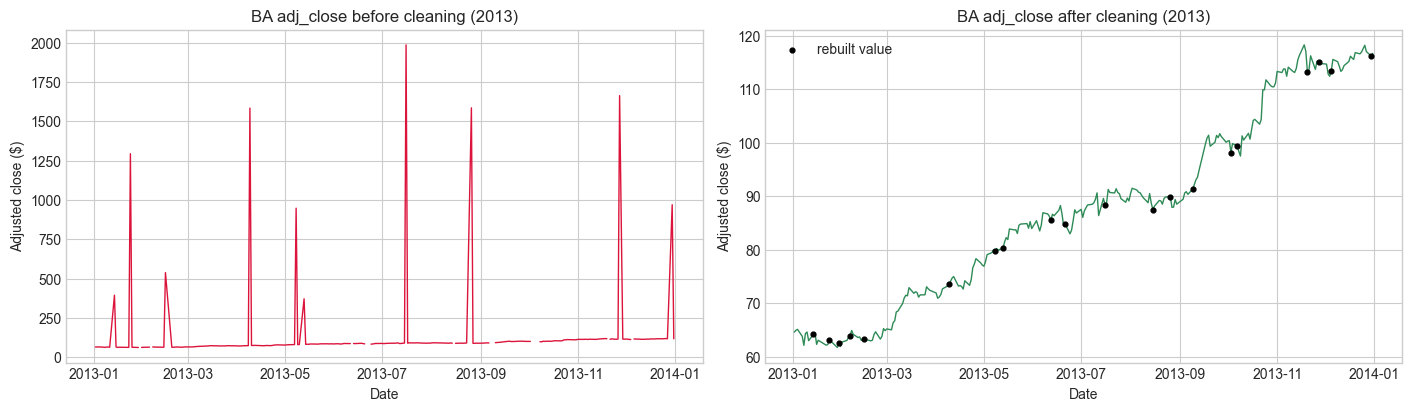

In [25]:
example = 'BA'
window = (data['ticker'] == example) & data['ts'].between('2013-01-01', '2013-12-31')
window_after = (cleaned['ticker'] == example) & cleaned['ts'].between('2013-01-01', '2013-12-31')
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
axes[0].plot(data.loc[window, 'ts'], data.loc[window, 'adj_close'], color='crimson', linewidth=1)
axes[0].set(title=f'{example} adj_close before cleaning (2013)', xlabel='Date', ylabel='Adjusted close ($)')
axes[1].plot(cleaned.loc[window_after, 'ts'], cleaned.loc[window_after, 'adj_close'], color='seagreen', linewidth=1)
repaired = window_after & cleaned['adj_close_repaired']
axes[1].scatter(cleaned.loc[repaired, 'ts'], cleaned.loc[repaired, 'adj_close'], s=12, color='black', label='rebuilt value', zorder=3)
axes[1].set(title=f'{example} adj_close after cleaning (2013)', xlabel='Date', ylabel='Adjusted close ($)')
axes[1].legend()
plt.show()

## Saving `ohlc_hw_cleaned`

In [26]:
def to_sql_dates(frame):
    """Copy with ts formatted as YYYY-MM-DD text."""
    out = frame.copy()
    out['ts'] = pd.to_datetime(out['ts']).dt.strftime('%Y-%m-%d')
    return out

columns = ['ts', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume',
           'price_repaired', 'price_repair_note', 'volume_repaired', 'adj_close_repaired', 'adj_close_repair_note',
           'extreme_return_flag', 'zero_volume_flag']
to_sql_dates(cleaned[columns]).to_sql('ohlc_hw_cleaned', conn, if_exists='replace', index=False)
to_sql_dates(quarantined).to_sql('ohlc_hw_quarantine', conn, if_exists='replace', index=False)
ticker_audit.to_sql('ohlc_hw_ticker_audit', conn, if_exists='replace', index=False)

saved = pd.read_sql_query('SELECT COUNT(*) AS rows, COUNT(DISTINCT ticker) AS tickers, MIN(ts) AS first, MAX(ts) AS last FROM ohlc_hw_cleaned', conn)
display(saved)
assert saved.loc[0, 'rows'] == len(cleaned)
roundtrip = pd.read_sql_query('SELECT * FROM ohlc_hw_cleaned WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts',
                              conn, params=('AAPL', '2024-06-01', '2024-11-30'))
assert len(roundtrip) == ((cleaned['ticker'] == 'AAPL') & cleaned['ts'].between('2024-06-01', '2024-11-30')).sum()
assert roundtrip['ts'].str.match(r'^\d{4}-\d{2}-\d{2}$').all()

assert pd.read_sql_query('SELECT COUNT(*) AS n FROM ohlc_hw', conn)['n'].iloc[0] == raw_row_count
conn.close()
print('Saved ohlc_hw_cleaned:', len(cleaned), 'rows |', 'quarantine:', len(quarantined), 'rows')

,rows,tickers,first,last
0,368246,30,1962-01-02,2024-12-06


Saved ohlc_hw_cleaned: 368246 rows | quarantine: 5 rows
